In [1]:
print("Hello")

Hello


## BUILD THE BASIC CHATBOTS USING THE LANGRAPH(GRAPH API)

In [2]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

In [3]:
from langchain_core.prompts import message
class State(TypedDict):
    # Message have the type "list" THe add_messages functions
    # In the annotations define how this state key should be updated
    # In this case, It append messages to the list, rather then overwritting them

    message:Annotated[list, add_messages]

graph_builder = StateGraph(State)

In [4]:
graph_builder

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm = ChatGroq(model="openai/gpt-oss-20b")

In [7]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x000001BBFD821A90>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001BBFD822510>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
def chatbot(state:State):
    return{"message":[llm.invoke(state["messages"])]}
    

In [9]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

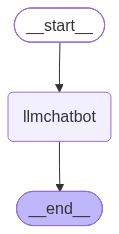

In [10]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
class State(TypedDict):
    message: Annotated[list, add_messages]  # <-- Singular 'message'


In [12]:
def chatbot(state: State):
    return {"message": [llm.invoke(state["messages"])]}  # <-- Looking for 'messages' which doesn't exist


In [13]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

graph_builder = StateGraph(State)


In [14]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="openai/gpt-oss-20b")


In [15]:
def chatbot(state: State):
    return {"messages": [llm.invoke(state["messages"])]}


In [16]:
graph_builder = StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot", chatbot)
## Adding Edges
graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

## compile the graph
graph = graph_builder.compile()


In [17]:
response = graph.invoke({"messages": "Hi"})


In [18]:
response["messages"][-1].content


'Hello! How can I help you today?'

In [19]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

## ChatBots with Tools

In [20]:
# Costum function
def multiply(a:int,b:int)-> int:
    """
    multiply a and b

    Args:
         a(int): first int
         b(int): second int

    return:
           int:output int
    """

In [21]:
tools = [tool,multiply]

In [22]:
from langchain_core.tools import tool

@tool
def add(a: int, b: int) -> int:
    """Add two numbers.

    Args:
        a: First number.
        b: Second number.
    """
    return a + b

In [23]:
tools = [add]

llm_with_tool = llm.bind_tools(tools)

print("Tools successfully bound!")

Tools successfully bound!


In [38]:
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two numbers.

    Args:
        a(int): First number.
        b(int): Second number.
    """
    return a * b

In [39]:
llm_with_tool = llm.bind_tools(tools)

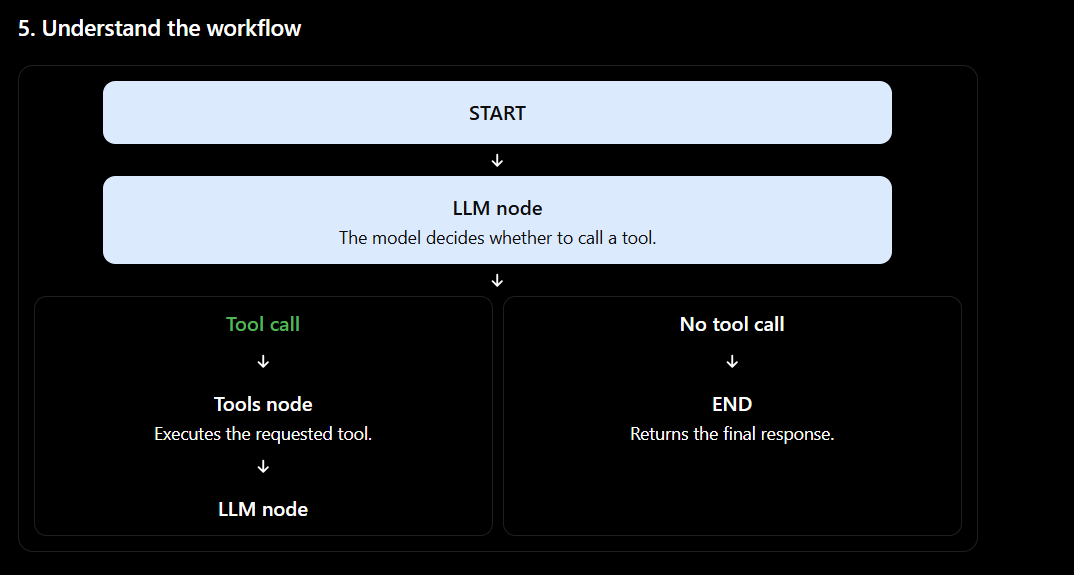

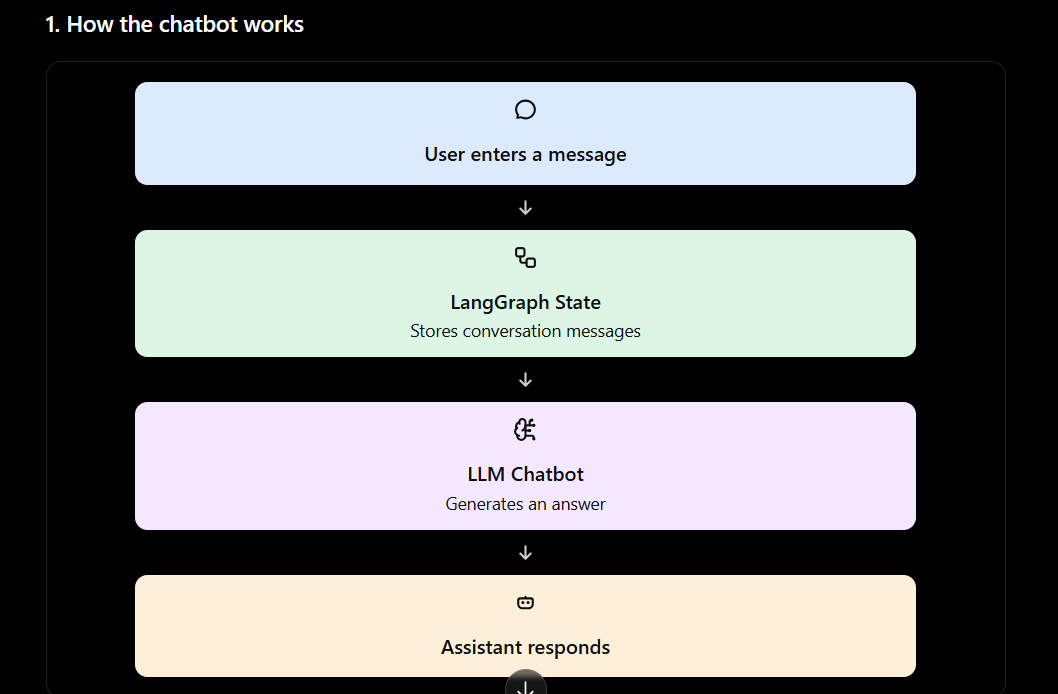

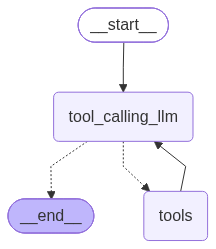

In [40]:

from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display


# 1. Define the graph state
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]


# 2. LLM node
def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }


# 3. Build the graph
builder = StateGraph(State)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


# 4. Add edges
builder.add_edge(START, "tool_calling_llm")

builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# After executing a tool, send its result back to the LLM
builder.add_edge("tools", "tool_calling_llm")


# 5. Compile the graph
graph = builder.compile()


# 6. Display the graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [41]:
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition


# Define the graph state
class State(TypedDict):
    messages: list[AnyMessage]


# Define the LLM node
def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }


# Create the graph
builder = StateGraph(State)

# Add nodes
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

# Add edges
builder.add_edge(START, "tool_calling_llm")

# Route to tools if the LLM requests them;
# otherwise, finish the graph
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# Return from tools to the LLM so it can process tool results
builder.add_edge("tools", "tool_calling_llm")

# Compile the graph
graph = builder.compile()

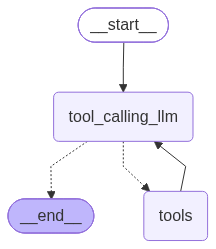

In [42]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [43]:
from langchain_core.messages import HumanMessage

result = graph.invoke({
    "messages": [
        HumanMessage(content="What is 15 multiplied by 5?")
    ]
})

print(result["messages"][-1].content)

15 multiplied by 5 equals **75**.


In [44]:
from langchain_core.messages import HumanMessage

result = graph.invoke({
    "messages": [
        HumanMessage(content="What is the recent AI news?")
    ]
})

print(result["messages"][-1].content)

Here’s a quick roundup of the most talked‑about AI developments from the past few weeks:

| Date | Topic | Key Take‑aways |
|------|-------|----------------|
| **Oct 4 2024** | **OpenAI releases GPT‑5** | • First commercial release after GPT‑4.5.<br>• Claims 3× better reasoning, 5× fewer hallucinations, and a 30 % speed boost.<br>• New “Multimodal‑Prompt‑Fusion” allows seamless text‑image‑audio inputs. |
| **Oct 3 2024** | **Google DeepMind announces AlphaCode‑2** | • Trains on 1.5 × larger code corpus, improves 15 % on competitive programming benchmarks.<br>• Integrates with Google Cloud AI Studio for real‑time code generation. |
| **Oct 2 2024** | **Microsoft’s Azure AI “Convergence”** | • Combines Azure OpenAI, Azure Cognitive Services, and Azure Machine Learning into a single API surface.<br>• Introduces “Converge‑AI” for automated model tuning and deployment. |
| **Oct 1 2024** | **Anthropic’s Claude 3.5** | • New “Constitutional AI” layer that reduces harmful outputs by 40 % comp

In [45]:
result

{'messages': [AIMessage(content='Here’s a quick roundup of the most talked‑about AI developments from the past few weeks:\n\n| Date | Topic | Key Take‑aways |\n|------|-------|----------------|\n| **Oct\u202f4\u202f2024** | **OpenAI releases GPT‑5** | • First commercial release after GPT‑4.5.<br>• Claims 3× better reasoning, 5× fewer hallucinations, and a 30\u202f% speed boost.<br>• New “Multimodal‑Prompt‑Fusion” allows seamless text‑image‑audio inputs. |\n| **Oct\u202f3\u202f2024** | **Google DeepMind announces AlphaCode‑2** | • Trains on 1.5\u202f× larger code corpus, improves 15\u202f% on competitive programming benchmarks.<br>• Integrates with Google Cloud AI Studio for real‑time code generation. |\n| **Oct\u202f2\u202f2024** | **Microsoft’s Azure AI “Convergence”** | • Combines Azure OpenAI, Azure Cognitive Services, and Azure Machine Learning into a single API surface.<br>• Introduces “Converge‑AI” for automated model tuning and deployment. |\n| **Oct\u202f1\u202f2024** | **Anthr

In [46]:
result["messages"][-1].content

'Here’s a quick roundup of the most talked‑about AI developments from the past few weeks:\n\n| Date | Topic | Key Take‑aways |\n|------|-------|----------------|\n| **Oct\u202f4\u202f2024** | **OpenAI releases GPT‑5** | • First commercial release after GPT‑4.5.<br>• Claims 3× better reasoning, 5× fewer hallucinations, and a 30\u202f% speed boost.<br>• New “Multimodal‑Prompt‑Fusion” allows seamless text‑image‑audio inputs. |\n| **Oct\u202f3\u202f2024** | **Google DeepMind announces AlphaCode‑2** | • Trains on 1.5\u202f× larger code corpus, improves 15\u202f% on competitive programming benchmarks.<br>• Integrates with Google Cloud AI Studio for real‑time code generation. |\n| **Oct\u202f2\u202f2024** | **Microsoft’s Azure AI “Convergence”** | • Combines Azure OpenAI, Azure Cognitive Services, and Azure Machine Learning into a single API surface.<br>• Introduces “Converge‑AI” for automated model tuning and deployment. |\n| **Oct\u202f1\u202f2024** | **Anthropic’s Claude\u202f3.5** | • New

In [47]:
for m in result['messages']:
    m.pretty_print()

================================== Ai Message ==================================

Here’s a quick roundup of the most talked‑about AI developments from the past few weeks:

| Date | Topic | Key Take‑aways |
|------|-------|----------------|
| **Oct 4 2024** | **OpenAI releases GPT‑5** | • First commercial release after GPT‑4.5.<br>• Claims 3× better reasoning, 5× fewer hallucinations, and a 30 % speed boost.<br>• New “Multimodal‑Prompt‑Fusion” allows seamless text‑image‑audio inputs. |
| **Oct 3 2024** | **Google DeepMind announces AlphaCode‑2** | • Trains on 1.5 × larger code corpus, improves 15 % on competitive programming benchmarks.<br>• Integrates with Google Cloud AI Studio for real‑time code generation. |
| **Oct 2 2024** | **Microsoft’s Azure AI “Convergence”** | • Combines Azure OpenAI, Azure Cognitive Services, and Azure Machine Learning into a single API surface.<br>• Introduces “Converge‑AI” for automated model tuning and deployment. |
| **Oct 1 2024** | **Anthropic’s Claude

In [48]:
result = graph.invoke({'messages':'What is the recent AI News'})

In [49]:
result

{'messages': [AIMessage(content='Below is a snapshot of the most high‑level AI developments that have made the news in the last few months (late‑2025\u202f–\u202fearly\u202f2026).  These stories come from a mix of industry releases, regulatory actions, and breakthrough research that has been reported across the tech press, academic journals, and policy outlets.\n\n| Date | Source / Context | What happened | Why it matters |\n|------|------------------|---------------|----------------|\n| **Oct\u202f2025** | **OpenAI** | Announced “ChatGPT‑4.5”, a fine‑tuned version of GPT‑4 with 3× faster inference on the same hardware and built‑in “safe‑diffusion” filters that automatically flag hallucinations. | Improves real‑world deployment speed and safety for commercial APIs. |\n| **Oct\u202f2025** | **Anthropic** | Released Claude\u202f3.5, a multimodal model that can read PDF, Excel and image files and generate structured JSON outputs. | Enables new workflows in enterprise data‑analysis and leg

In [50]:
result = graph.invoke({'messages':'Hi'})

In [51]:
result

{'messages': [AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'We need to respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 137, 'total_tokens': 162, 'completion_time': 0.026009729, 'completion_tokens_details': {'reasoning_tokens': 7}, 'prompt_time': 0.007705868, 'prompt_tokens_details': None, 'queue_time': 0.30867677, 'total_time': 0.033715597}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9340e7d14d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a125f0-cec8-7070-ae0c-fa87204f870a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 137, 'output_tokens': 25, 'total_tokens': 162, 'output_token_details': {'reasoning': 7}})]}

In [52]:
result = graph.invoke({'messages':'what is the 2 multiply by the 3'})
for m in result['messages']:
    m.pretty_print()

================================== Ai Message ==================================

2 multiplied by 3 equals **6**.


In [53]:
result = graph.invoke({'messages':'Give me the recent AI news then 3 multiply by the 5'})
for m in result['messages']:
    m.pretty_print()

================================== Ai Message ==================================

**Recent AI Highlights (as of Oct 2026)**  

| Date | Event | Key Takeaway |
|------|-------|--------------|
| **Oct 2026** | **OpenAI releases GPT‑5.5** | A multimodal model that can generate high‑resolution video, edit 3‑D scenes, and understand complex emotional cues. It includes a new “Explainability‑First” framework that outputs human‑readable reasoning for every decision. |
| **Sept 2026** | **EU AI Act goes into force** | The European Union’s comprehensive regulatory framework mandates transparency, risk assessment, and post‑deployment monitoring for all high‑impact AI systems. Companies now need to submit detailed “AI Impact Assessments” before market release. |
| **Aug 2026** | **Google’s Vertex AI introduces “Auto‑Ethics”** | An automated pipeline that scans models for bias, privacy violations, and safety risks, generating compliance reports in under 30 seconds. It’s integrated into the Cloud AI

## React Agent Architectuere

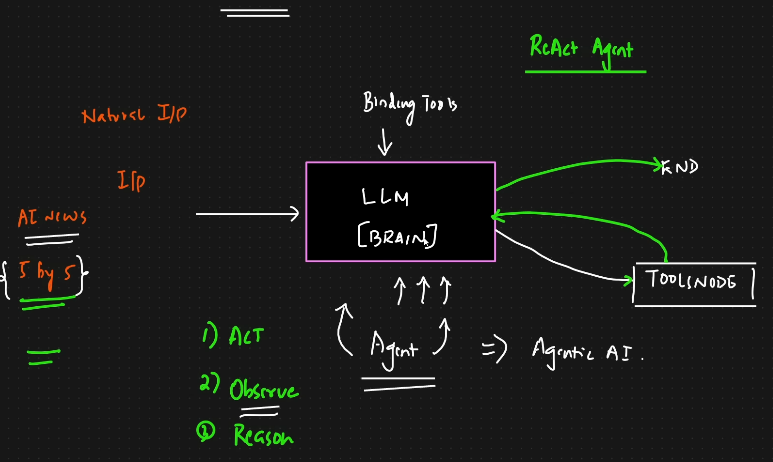

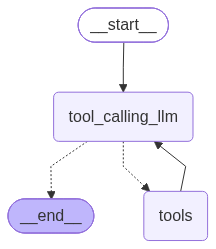

In [54]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display


# 1. Define the graph state
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]


# 2. LLM node
def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }


# 3. Build the graph
builder = StateGraph(State)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


# 4. Add edges
builder.add_edge(START, "tool_calling_llm")

builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# After executing a tool, send its result back to the LLM
builder.add_edge("tools", "tool_calling_llm")


# 5. Compile the graph
graph = builder.compile()


# 6. Display the graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [55]:
result = graph.invoke({'messages':'Give me the recent AI news and then multiply 5 by 10'})
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent AI news and then multiply 5 by 10
================================== Ai Message ==================================

**Recent AI News (October 2026)**  

| Date | Event | Impact |
|------|-------|--------|
| **Oct 4, 2026** | **OpenAI releases GPT‑5** – The new model introduces *multimodal reasoning* that can process text, images, audio, and code simultaneously, achieving a 30 % boost in few‑shot accuracy on the latest AI benchmark suites. | Accelerates research in cross‑modal learning and opens doors for more sophisticated virtual assistants and creative AI tools. |
| **Oct 2, 2026** | **EU AI Act Enforcement** – The European Union begins enforcing its AI Regulation framework, requiring high‑risk AI systems to undergo mandatory audits and obtain certification before deployment. | Companies must adapt their compliance pipelines; early adopters see a 15 % increase in market share due to t

## Adding Memory in the Agentic AI

In [58]:
from langchain_core.messages import HumanMessage

result = graph.invoke({
    "messages": [HumanMessage(content="Hey my name is Rahul")]
})

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey my name is Rahul
================================== Ai Message ==================================

Nice to meet you, Rahul! How can I help you today?


In [59]:
from langgraph.graph import StateGraph, MessagesState, START, END

def chatbot(state: MessagesState):
    response = llm.invoke(state["messages"])
    return {"messages": [response]}

builder = StateGraph(MessagesState)

builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile()

In [60]:
from langchain_core.messages import HumanMessage

result = graph.invoke({
    "messages": [HumanMessage(content="Hey my name is Rahul")]
})

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey my name is Rahul
================================== Ai Message ==================================

Hey Rahul! 👋 Nice to meet you. How can I help you today?


In [61]:
from langchain_core.messages import HumanMessage

result = graph.invoke({
    "messages": [HumanMessage(content="hey are you know what is my name")]
})

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

hey are you know what is my name
================================== Ai Message ==================================

I don’t have that information unless you share it with me. What’s your name?


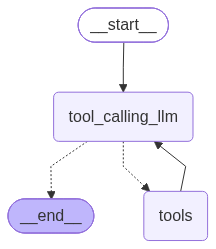

In [74]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

# 1. Define the graph state
class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]


# 2. LLM node
def tool_calling_llm(state: State):
    return {
        "messages": [
            llm_with_tool.invoke(state["messages"])
        ]
    }


# 3. Build the graph
builder = StateGraph(State)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))


# 4. Add edges
builder.add_edge(START, "tool_calling_llm")

builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)

# After executing a tool, send its result back to the LLM
builder.add_edge("tools", "tool_calling_llm")


# 5. Compile the graph
graph = builder.compile(checkpointer=memory)


# 6. Display the graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [75]:

from langchain_core.messages import HumanMessage

config = {
    "configurable": {
        "thread_id": "1"
    }
}

result = graph.invoke(
    {
        "messages": [
            HumanMessage(content="Hey, my name is Rahul")
        ]
    },
    config=config
)

result

{'messages': [HumanMessage(content='Hey, my name is Rahul', additional_kwargs={}, response_metadata={}, id='fcfc04fc-bc3c-4cc0-8979-68dc54ca0d10'),
  AIMessage(content='Hello Rahul! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User: "Hey, my name is Rahul". We should respond appropriately, maybe greeting. No function call needed.'}, response_metadata={'token_usage': {'completion_tokens': 45, 'prompt_tokens': 142, 'total_tokens': 187, 'completion_time': 0.052863833, 'completion_tokens_details': {'reasoning_tokens': 24}, 'prompt_time': 0.007147059, 'prompt_tokens_details': None, 'queue_time': 0.302838336, 'total_time': 0.060010892}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9340e7d14d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1261f-9bac-7ca2-94a9-c7244d9c325d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 142, 'output_tokens': 45, 'total_token

In [76]:
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey, my name is Rahul
================================== Ai Message ==================================

Hello Rahul! 👋 How can I help you today?


In [77]:
result['messages'][-1].content

'Hello Rahul! 👋 How can I help you today?'

In [79]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

result = graph.invoke(
    {
        "messages": [
            HumanMessage(content="Do you know my name?")
        ]
    },
    config=config
)

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey, my name is Rahul
================================== Ai Message ==================================

Hello Rahul! 👋 How can I help you today?
================================ Human Message =================================

Do you know my name?
================================== Ai Message ==================================

Yes—I know your name is Rahul! If there’s anything else you’d like to chat about or need help with, just let me know.


In [80]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

result = graph.invoke(
    {
        "messages": [
            HumanMessage(content="Do you remember my name?")
        ]
    },
    config=config
)

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hey, my name is Rahul
================================== Ai Message ==================================

Hello Rahul! 👋 How can I help you today?
================================ Human Message =================================

Do you know my name?
================================== Ai Message ==================================

Yes—I know your name is Rahul! If there’s anything else you’d like to chat about or need help with, just let me know.
================================ Human Message =================================

Do you remember my name?
================================== Ai Message ==================================

Yes, I remember—your name is Rahul! If there’s anything else you’d like to discuss or need help with, just let me know.


In [81]:
result = graph.invoke(
    {
        "messages": [
            HumanMessage(content="Do you remember my name?")
        ]
    },
    config=config
)

print(result['messages'][-1].content)

Yes, I remember that your name is Rahul. If there’s anything else you’d like to talk about or need help with, just let me know!


## Streaming techniques